In [ ]:
%pip install numpy cupy pandas matplotlib scikit-learn seaborn cuml


# MULTI-DATASET E-COMMERCE ORDER RETURN CLASSIFICATION

In [ ]:
# For GPU acceleration
%load_ext cuml.accel


In [ ]:
import os
import gc
import re
import joblib
import warnings
import cupy as np
# import nump as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV,
    cross_val_score
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore")


## 1. CONFIGURATION

DATASET_CONFIG is a dictionary containing the configuration for each dataset, including the file path, target column, train-test split ratio, cv folds, and any columns to drop or treat as leakage etc.


In [ ]:
DATASET_CONFIG = {
    "Ecommerce_2000": {
        "file": "processed_datasets/Ecommerce_2000.csv",
        "target": "returned",
        "positive_class": 1,
        "categorical_columns": ["OrderYear"],
        "test_size": 0.2,
        "cv_folds": 10,
    },

    "Retail_Return_Risk": {
        "file": "processed_datasets/retail_return_risk.csv",
        "target": "returned",
        "positive_class": 1,
        "categorical_columns": [],
        "test_size": 0.4,
        "cv_folds": 3,
    },

    "BADS_WS2021_known": {
        "file": "processed_datasets/BADS_WS2021_known.csv",
        "target": "returned",
        "positive_class": 1,
        "categorical_columns": ["item_id", "brand_id", "user_id"],
        "test_size": 0.4,
        "cv_folds": 3,
    },
}


RANDOM_STATE = 42

SCORING = "roc_auc"

# no of CPU cores to use for parallel processing (-1 means using all available cores)
N_JOBS = -1

USE_CLASS_WEIGHT = True

OUTPUT_DIR = "results"

INDIVIDUAL_DIR = os.path.join(OUTPUT_DIR, "individual_results")

PLOT_DIR = os.path.join(OUTPUT_DIR, "plots")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(INDIVIDUAL_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)


## 2. PREPROCESSING HELPER FUNCTIONS

Standard Scaler for numerical features and One Hot Encoder for categorical features.

In [ ]:
def safe_name(name):
    return re.sub(r"[^a-zA-Z0-9_-]", "_", str(name))

# One Hot encoding for categorical features
# Standard Scaling for numerical features


def make_preprocessor(X, categorical_columns=[]) -> tuple[pd.DataFrame, ColumnTransformer, list[str], list[str]]:
    numeric = X.select_dtypes(
        include=["number"]
    ).columns.tolist()
    numeric = [col for col in numeric if col not in categorical_columns]

    categorical = X.select_dtypes(
        include=["object", "category", "bool", "string"]
    ).columns.tolist()
    categorical.extend(
        [col for col in categorical_columns if col in X.columns])

    # Treat categorical values consistently.
    X = X.copy()

    for col in categorical:
        if col in X.columns:
            X[col] = X[col].astype("string")

    num_pipeline = Pipeline([
        ("scaler", StandardScaler())
    ])

    cat_pipeline = Pipeline([
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])

    preprocessor = ColumnTransformer([
        ("num", num_pipeline, numeric),
        ("cat", cat_pipeline, categorical)
    ], sparse_threshold=0.0)

    return X, preprocessor, numeric, categorical


## 3. MODEL CONFIGURATIONS

A list of dictionaries, each containing a model pipeline, hyperparameter grid, CV search type (grid or random), and number of iterations for random search.

In [ ]:
def get_models():
    class_weight = ("balanced" if USE_CLASS_WEIGHT else None)

    models = {
        "Logistic": {
            "pipeline": Pipeline([
                ("preprocessor", None),
                ("model", LogisticRegression(
                    class_weight=class_weight,
                    random_state=RANDOM_STATE
                ))
            ]),
            "params": [
                {
                    "model__max_iter": [100, 200, 500, 1000],
                    "model__penalty": ["l1"],
                    "model__solver": ["saga"],
                    "model__C": [0.01, 0.1, 1, 10, 100]
                },
                {
                    "model__max_iter": [100, 200, 500, 1000],
                    "model__penalty": ["l2"],
                    "model__solver": ["lbfgs"],
                    "model__C": [0.01, 0.1, 1, 10, 100]
                },
                {
                    "model__max_iter": [100, 200, 500, 1000],
                    "model__penalty": ["elasticnet"],
                    "model__solver": ["saga"],
                    "model__C": [0.01, 0.1, 1, 10, 100],
                    "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]
                }
            ],
            "search_type": "random",
            "random_search_iterations": 40
        },
        # "Gaussian Naive Bayes": {
        #     "pipeline": Pipeline([
        #         ("preprocessor", None),
        #         ("model", GaussianNB())
        #     ]),
        #     "params": {
        #         "model__var_smoothing": [1e-12, 1e-10, 1e-9, 1e-8, 1e-7]
        #     },
        #     "search_type": "grid"
        # },
        "LDA": {
            "pipeline": Pipeline([
                ("preprocessor", None),
                ("model", LinearDiscriminantAnalysis())
            ]),
            "params": [
                {
                    "model__solver": ["svd"]
                },
                {
                    "model__solver": ["lsqr", "eigen"],
                    "model__shrinkage": ["auto", 0.1, 0.3, 0.5, 0.7]
                }
            ],
            "search_type": "grid",
        },
        "QDA": {
            "pipeline": Pipeline([
                ("preprocessor", None),
                ("model", QuadraticDiscriminantAnalysis())
            ]),
            "params": [
                {
                    "model__solver": ["svd"],
                    "model__reg_param": [0.0, 0.1, 0.25, 0.5, 0.75, 0.9],
                },
                {
                    "model__solver": ["eigen"],
                    "model__reg_param": [0.0, 0.1, 0.25, 0.5, 0.75, 0.9],
                    "model__shrinkage": ["auto", 0.1, 0.3, 0.5, 0.7]
                }
            ],
            "search_type": "grid"
        },
        # "Decision Tree": {
        #     "pipeline": Pipeline([
        #         ("preprocessor", None),
        #         ("model", DecisionTreeClassifier(
        #             random_state=RANDOM_STATE,
        #             class_weight=class_weight
        #         ))
        #     ]),
        #     "params": {
        #         "model__criterion": ["gini", "entropy"],
        #         "model__max_depth": [None, 5, 10, 20],
        #         "model__min_samples_split": [2, 5, 10],
        #         "model__min_samples_leaf": [1, 2, 5],
        #         "model__max_features": [None, "sqrt"]
        #     },
        #     "search_type": "random",
        #     "random_search_iterations": 40
        # },
        "Random Forest": {
            "pipeline": Pipeline([
                ("preprocessor", None),
                ("model", RandomForestClassifier(
                    random_state=RANDOM_STATE,
                    n_jobs=N_JOBS,
                    class_weight=class_weight
                ))
            ]),
            "params": {
                "model__n_estimators": [100, 200, 400],
                "model__max_depth": [None, 5, 10, 20],
                "model__min_samples_split": [2, 5, 10],
                "model__min_samples_leaf": [1, 2, 5],
                "model__max_features": ["sqrt", "log2"],
                "model__bootstrap": [True, False]
            },
            "search_type": "random",
            "random_search_iterations": 40
        },
        "KNN": {
            "pipeline": Pipeline([
                ("preprocessor", None),
                ("model", KNeighborsClassifier(n_jobs=N_JOBS))
            ]),
            "params": {
                "model__n_neighbors": [3, 5, 7, 9, 11, 13, 15, 17, 19, 21],
                "model__weights": ["uniform", "distance"],
                "model__p": [1, 2],
                "model__leaf_size": [20, 30, 40]
            },
            "search_type": "random",
            "random_search_iterations": 40
        }
    }
    return models


## 4. EVALUATION FUNCTION

Takes the trained model and evaluates it on the test set, returning a dictionary of evaluation metrics.

In [ ]:
def evaluate_model(
    name,
    model,
    X_test,
    y_test,
    dataset_name,
    cv_score
) -> tuple[dict[str, any], np.ndarray, np.ndarray]:

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    metrics = {
        "Dataset": dataset_name,
        "Model": name,
        "CV_{}".format(SCORING): cv_score,

        "Accuracy": accuracy_score(y_test, y_pred),
        "Error_Rate": 1 - accuracy_score(y_test, y_pred),
        "Balanced_Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "Specificity": specificity,
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, y_prob),
        "PR_AUC": average_precision_score(y_test, y_prob),
        "Log_Loss": log_loss(y_test, y_prob, labels=[0, 1]),
        "Brier_Score": brier_score_loss(y_test, y_prob),

        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

    return metrics, y_pred, y_prob


## 5. PROCESS ONE DATASET

This function takes a dataset configuration, loads the data, preprocesses it, trains multiple models using grid search or random search, evaluates them, and returns the best model along with its evaluation metrics.

In [ ]:
def process_dataset(dataset_name, config):
    file_path = config["file"]
    target = config["target"]
    positive_class = config["positive_class"]
    categorical_columns = config["categorical_columns"]

    test_size = config.get("test_size", 0.2)
    cv_folds = config.get("cv_folds", 5)

    dataset_name = os.path.splitext(
        os.path.basename(file_path)
    )[0]

    print("\n" + "#" * 80)
    print("PROCESSING DATASET:", dataset_name)
    print("#" * 80)

    # Load dataset
    df = pd.read_csv(file_path)
    print("Shape:", df.shape)

    if target not in df.columns:
        raise ValueError(f"Target '{target}' not found.")

    original_classes = list(pd.unique(df[target]))

    if positive_class is not None:
        if positive_class not in original_classes:
            raise ValueError(
                f"Positive class {positive_class} not found. Available: {original_classes}")

        positive_label = positive_class
        negative_label = next(
            c for c in original_classes if c != positive_label)
        y = (df[target] == positive_label).astype(int)

    else:
        encoder = LabelEncoder()
        y = pd.Series(encoder.fit_transform(df[target]), index=df.index)
        negative_label, positive_label = encoder.classes_

    X = df.drop(columns=[target]).copy()

    X, preprocessor, numeric, categorical = make_preprocessor(
        X, categorical_columns)

    print("Numerical features:", len(numeric))
    print("Categorical features:", len(categorical))

    # Train-test split with stratification to maintain class distribution
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=RANDOM_STATE,
        stratify=y
    )

    min_class = int(y_train.value_counts().min())
    if min_class < 2:
        raise ValueError("Not enough examples for stratified CV.")

    # Cross-validation setup with stratified folds to maintain class distribution
    n_splits = min(cv_folds, min_class)
    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    print("Training samples:", len(X_train))
    print("Testing samples:", len(X_test))
    print("CV folds:", n_splits)

    dataset_info = {
        "Dataset": dataset_name,
        "Original_Rows": len(df),
        "Features": X.shape[1],
        "Numerical_Features": len(numeric),
        "Categorical_Features": len(categorical),
        "Train_Size": len(X_train),
        "Test_Size": len(X_test),
        "Negative_Count": int((y == 0).sum()),
        "Positive_Count": int((y == 1).sum()),
        "Return_Rate": float(y.mean())
    }

    models = get_models()

    dataset_results = []
    dataset_predictions = {}
    trained_models = {}
    best_parameters = []

    # Iterate through each model configuration
    for name, config in models.items():
        print("\n" + "-" * 70)
        print("MODEL:", name)
        print("-" * 70)

        pipeline = None
        best_model = None
        search = None

        SEARCH_TYPE = config.get("search_type", "grid")
        RANDOM_SEARCH_ITERATIONS = config.get("random_search_iterations", 20)

        try:
            pipeline = clone(config["pipeline"])
            pipeline.set_params(preprocessor=clone(preprocessor))

            params = config["params"]

            # Perform hyperparameter search if parameters are provided
            if params is not None:
                if SEARCH_TYPE == "grid":
                    search = GridSearchCV(
                        estimator=pipeline,
                        param_grid=params,
                        scoring=SCORING,
                        cv=cv,
                        n_jobs=N_JOBS,
                        pre_dispatch=1,
                        refit=True,
                        verbose=0,
                        error_score=np.nan
                    )
                else:
                    search = RandomizedSearchCV(
                        estimator=pipeline,
                        param_distributions=params,
                        scoring=SCORING,
                        cv=cv,
                        n_jobs=N_JOBS,
                        pre_dispatch=1,
                        refit=True,
                        verbose=0,
                        error_score=np.nan,
                        random_state=RANDOM_STATE,
                        n_iter=RANDOM_SEARCH_ITERATIONS,
                    )

                search.fit(X_train, y_train)

                if not np.isfinite(search.best_score_):
                    raise ValueError(
                        "All hyperparameter configurations failed.")

                best_model = search.best_estimator_
                cv_score = search.best_score_

                best_parameters.append({
                    "Dataset": dataset_name,
                    "Model": name,
                    "Best_CV_{}".format(SCORING): cv_score,
                    "Best_Parameters": str(search.best_params_)
                })

                print("Best CV {}:".format(SCORING), cv_score)
                print("Best parameters:", search.best_params_)

            # If no hyperparameter search is performed, evaluate the default model
            else:
                cv_scores = cross_val_score(
                    pipeline,
                    X_train,
                    y_train,
                    scoring=SCORING,
                    cv=cv,
                    n_jobs=N_JOBS
                )

                cv_score = cv_scores.mean()
                best_model = pipeline.fit(X_train, y_train)
                best_parameters.append({
                    "Dataset": dataset_name,
                    "Model": name,
                    "Best_CV_{}".format(SCORING): cv_score,
                    "Best_Parameters": "Default / None"
                })
                print("CV {}:".format(SCORING), cv_score)

            # Evaluate the best model on the test set
            metrics, y_pred, y_prob = evaluate_model(
                name,
                best_model,
                X_test,
                y_test,
                dataset_name,
                cv_score
            )

            # Store results and predictions
            dataset_results.append(metrics)
            dataset_predictions[name] = {
                "actual": y_test.values,
                "predicted": y_pred,
                "probability": y_prob
            }

            trained_models[name] = best_model

            # Display classification report
            print(
                classification_report(
                    y_test,
                    y_pred,
                    target_names=[str(negative_label), str(positive_label)],
                    zero_division=0
                )
            )

        except Exception as e:
            print(f"\n[FAILED] {name}")
            print(f"Reason: {type(e).__name__}: {e}")
            dataset_results.append({
                "Dataset": dataset_name,
                "Model": name,
                "Status": "Failed",
                "Error": f"{type(e).__name__}: {e}"
            })

        finally:
            del search
            del pipeline
            gc.collect()

    # Save results
    result_df = pd.DataFrame(dataset_results)

    if "Status" not in result_df.columns:
        result_df["Status"] = "Success"

    successful = result_df[result_df["Status"] != "Failed"]
    failed = result_df[result_df["Status"] == "Failed"]

    if "PR_AUC" in successful.columns:
        successful = successful.sort_values("PR_AUC", ascending=False)

    result_df = pd.concat([successful, failed], ignore_index=True)

    folder = os.path.join(INDIVIDUAL_DIR, safe_name(dataset_name))
    os.makedirs(folder, exist_ok=True)

    result_df.to_csv(os.path.join(folder, "model_results.csv"), index=False)

    pd.DataFrame(best_parameters).to_csv(
        os.path.join(folder, "best_parameters.csv"),
        index=False
    )

    joblib.dump(trained_models, os.path.join(folder, "trained_models.pkl"))

    # Save predictions
    prediction_df = pd.DataFrame({
        "Actual": y_test.values
    }, index=y_test.index)

    for name, pred in dataset_predictions.items():
        key = safe_name(name)
        prediction_df[key + "_prediction"] = (pred["predicted"])
        prediction_df[key + "_probability"] = (pred["probability"])

    prediction_df.to_csv(os.path.join(folder, "test_predictions.csv"))

    if dataset_predictions:
        fig, axes = plt.subplots(2, 4, figsize=(20, 10))
        axes = axes.flatten()

        for i, (name, pred) in enumerate(dataset_predictions.items()):
            cm = confusion_matrix(
                pred["actual"],  pred["predicted"], labels=[0, 1])

            sns.heatmap(
                cm,
                annot=True,
                fmt="d",
                cmap="Blues",
                ax=axes[i],
                xticklabels=[negative_label, positive_label],
                yticklabels=[negative_label, positive_label]
            )

            axes[i].set_title(name)
            axes[i].set_xlabel("Predicted")
            axes[i].set_ylabel("Actual")

        plt.tight_layout()
        plt.show()
        plt.savefig(os.path.join(folder, "confusion_matrices.png"), dpi=200)
        plt.close()

        fig, axes = plt.subplots(1, 2, figsize=(16, 6))

        for name, pred in dataset_predictions.items():
            fpr, tpr, _ = roc_curve(pred["actual"], pred["probability"])
            auc = roc_auc_score(pred["actual"], pred["probability"])
            axes[0].plot(fpr, tpr, label=f"{name} ({auc:.3f})")
            precision, recall, _ = precision_recall_curve(
                pred["actual"], pred["probability"])
            ap = average_precision_score(pred["actual"], pred["probability"])
            axes[1].plot(recall, precision,  label=f"{name} ({ap:.3f})")

        axes[0].plot([0, 1], [0, 1], linestyle="--", color="black")

        axes[0].set_title("ROC Curves")
        axes[0].set_xlabel("False Positive Rate")
        axes[0].set_ylabel("True Positive Rate")

        axes[1].set_title("Precision-Recall Curves")
        axes[1].set_xlabel("Recall")
        axes[1].set_ylabel("Precision")

        for ax in axes:
            ax.legend(fontsize=8)
            ax.grid(alpha=0.3)

        plt.tight_layout()
        plt.show()
        plt.savefig(os.path.join(folder, "roc_pr_curves.png"), dpi=200)
        plt.close()
    else:
        print("No successful models to plot.")

    print("\nCompleted:", dataset_name)

    return dataset_info, dataset_results, best_parameters


## 6. PROCESS ALL DATASETS

In [ ]:
all_results = []
all_dataset_info = []
all_parameters = []
failed_datasets = []

for dataset_name, config in DATASET_CONFIG.items():
    info, results, parameters = process_dataset(dataset_name, config)
    all_dataset_info.append(info)
    all_results.extend(results)
    all_parameters.extend(parameters)

if not all_results:
    raise RuntimeError("No datasets were successfully processed.")

all_results_df = pd.DataFrame(all_results)
dataset_info_df = pd.DataFrame(all_dataset_info)
parameters_df = pd.DataFrame(all_parameters)

all_results_df.to_csv(os.path.join(
    OUTPUT_DIR, "all_model_results.csv"), index=False
)
dataset_info_df.to_csv(
    os.path.join(OUTPUT_DIR, "dataset_information.csv"),
    index=False
)
parameters_df.to_csv(
    os.path.join(OUTPUT_DIR, "all_best_parameters.csv"),
    index=False
)



################################################################################
PROCESSING DATASET: Ecommerce_2000
################################################################################
Shape: (1650, 22)
Numerical features: 12
Categorical features: 9
Training samples: 1320
Testing samples: 330
CV folds: 10

----------------------------------------------------------------------
MODEL: Logistic
----------------------------------------------------------------------
[2026-11-12 17:15:41.641] [CUML] [warning] QWL-QN: max iterations reached
[2026-11-12 17:15:41.641] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number of iterations (max_iter) or improve the scaling of the input data.
[2026-11-12 17:15:42.216] [CUML] [warning] QWL-QN: max iterations reached
[2026-11-12 17:15:42.217] [CUML] [warning] Maximum iterations reached before solver is converged. To increase model accuracy you can increase the number 

KeyError: 'Column not found: F2'

Dataset: Ecommerce_2000
Detected models: ['Logistic', 'LDA', 'QDA', 'Random_Forest', 'KNN']


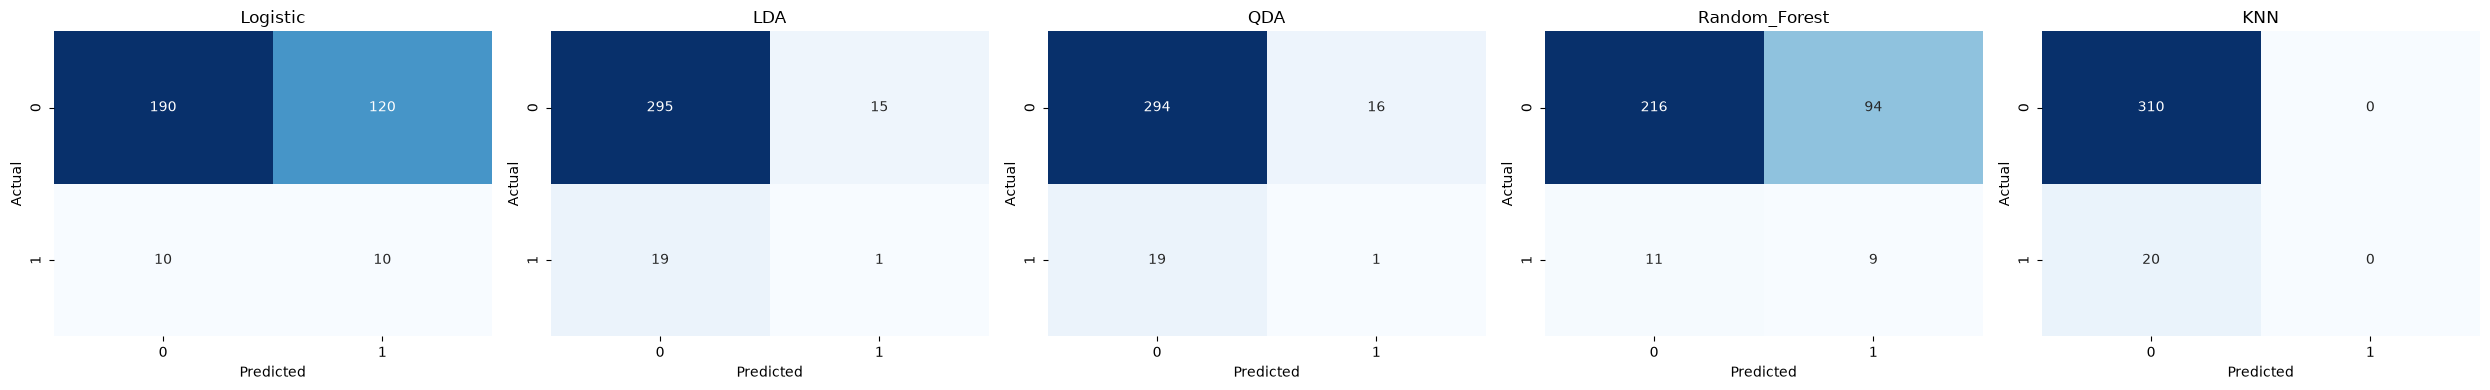

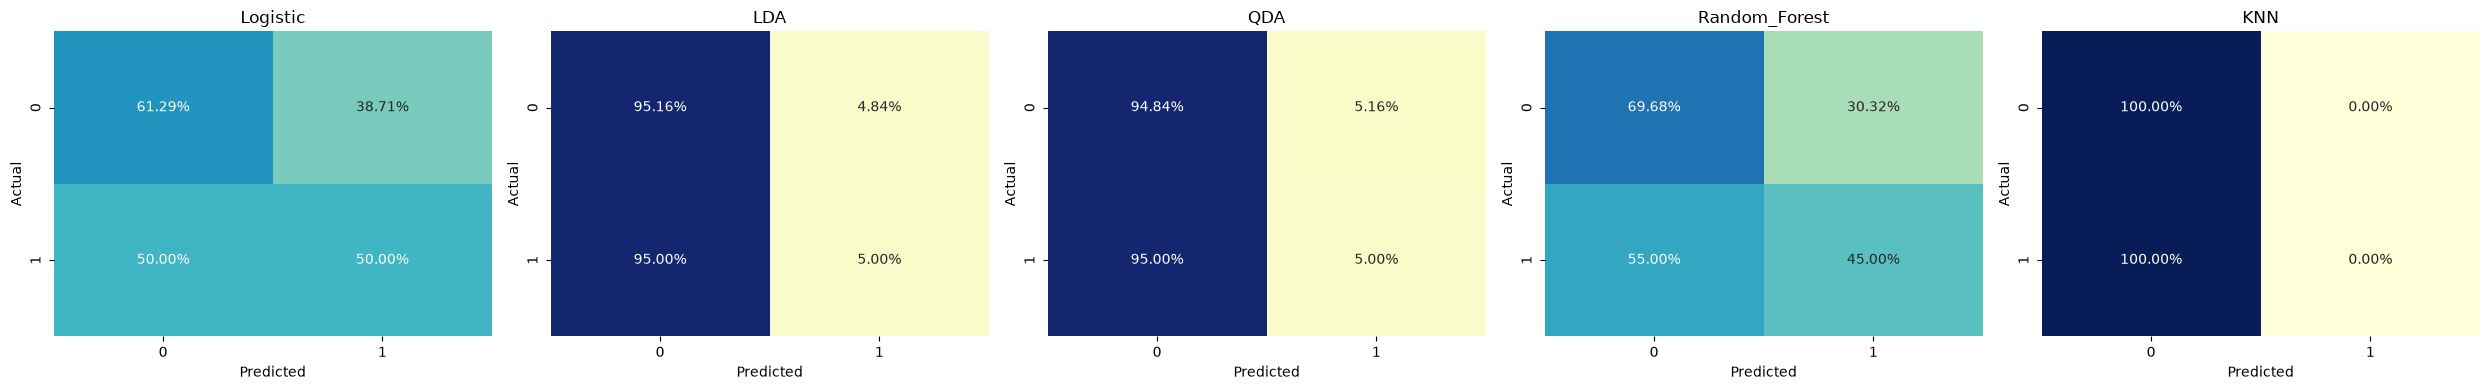

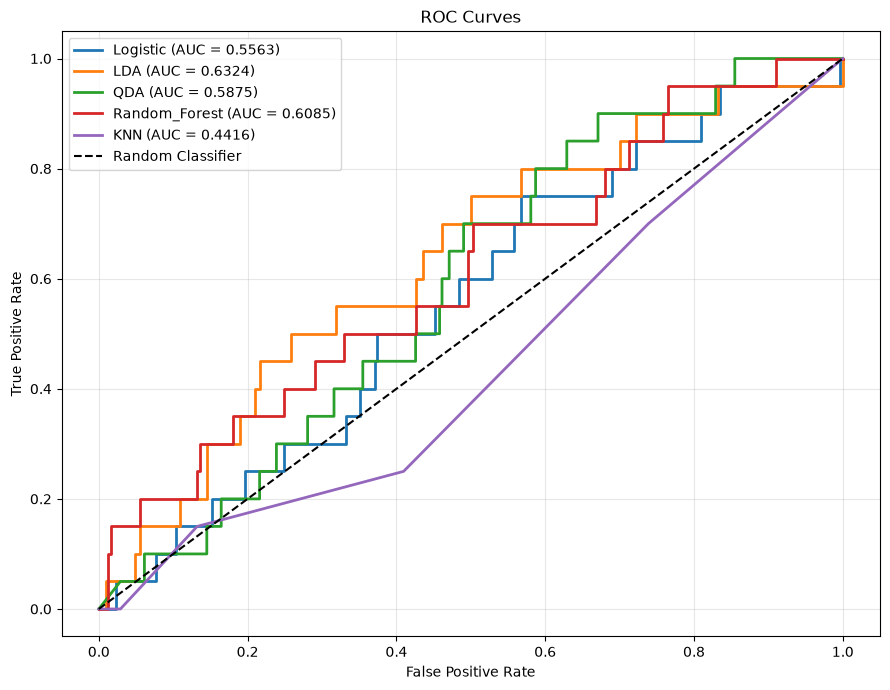

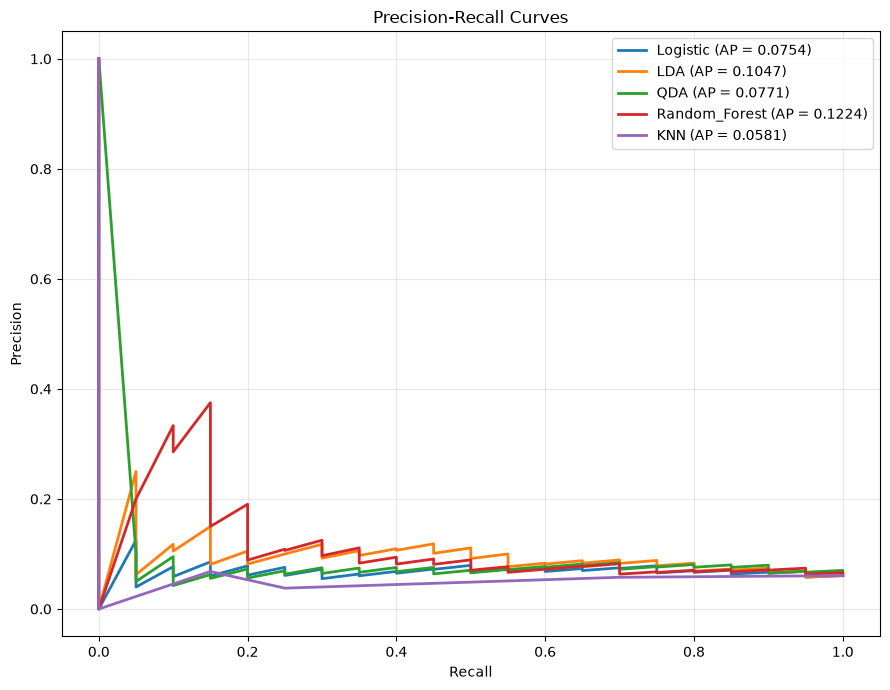


Model Comparison:
                ROC-AUC  PR-AUC (AP)
Random_Forest  0.608548     0.122420
LDA            0.632419     0.104694
QDA            0.587500     0.077145
Logistic       0.556290     0.075400
KNN            0.441613     0.058123


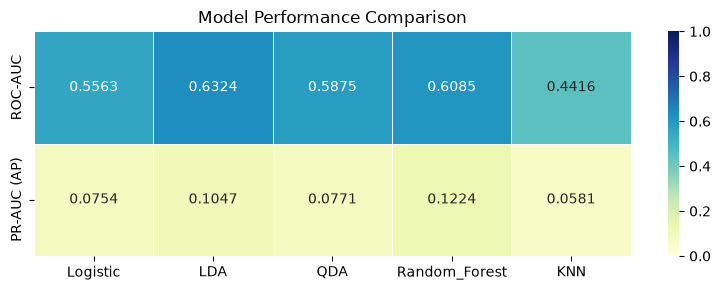

Dataset: Retail_Return_Risk
Detected models: ['Logistic', 'LDA', 'QDA', 'Random_Forest', 'KNN']


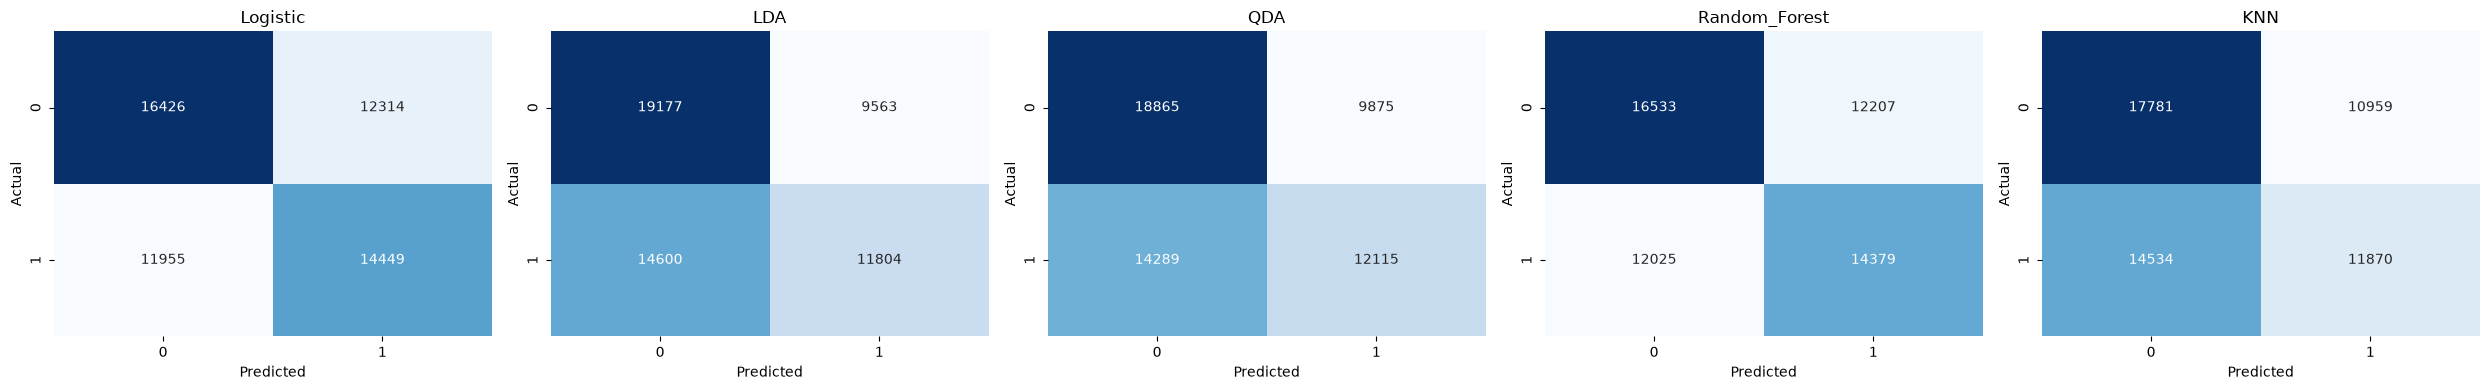

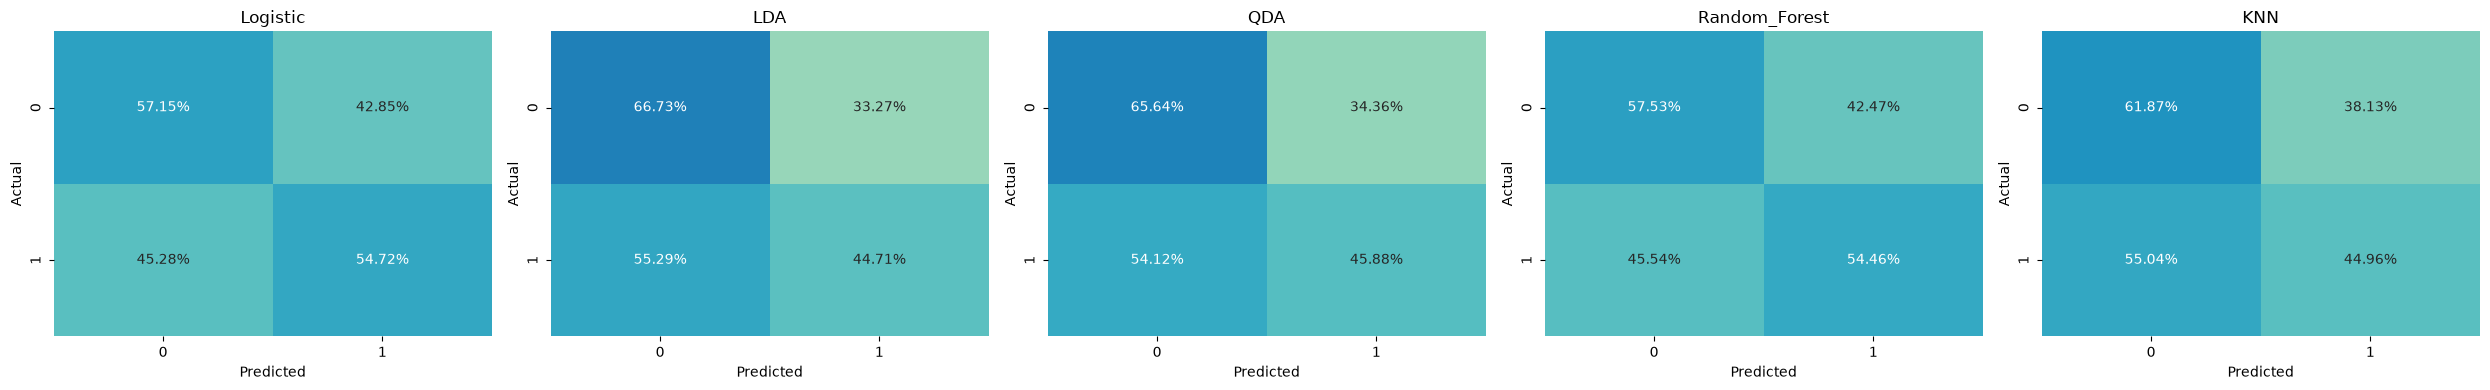

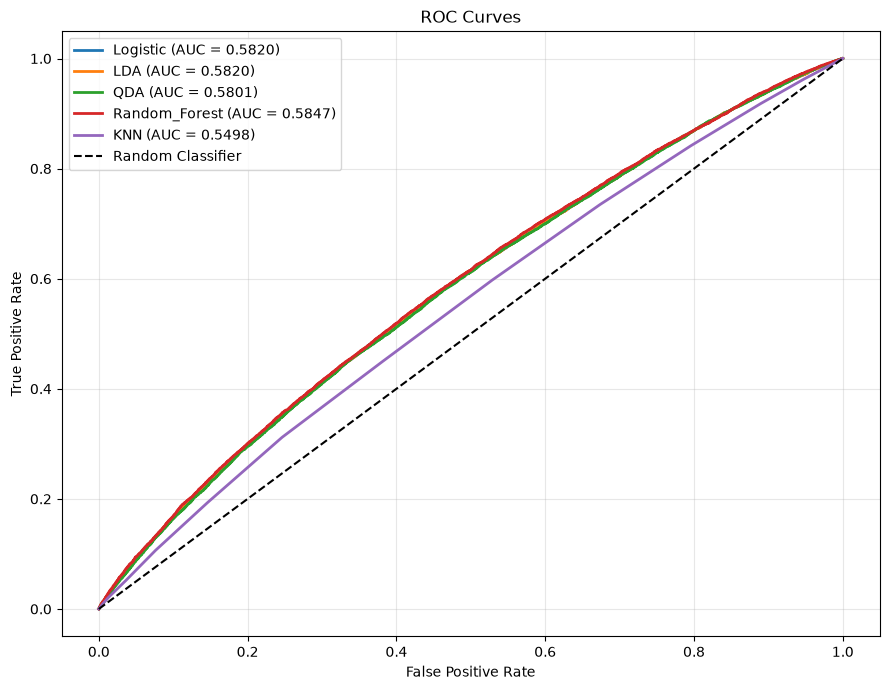

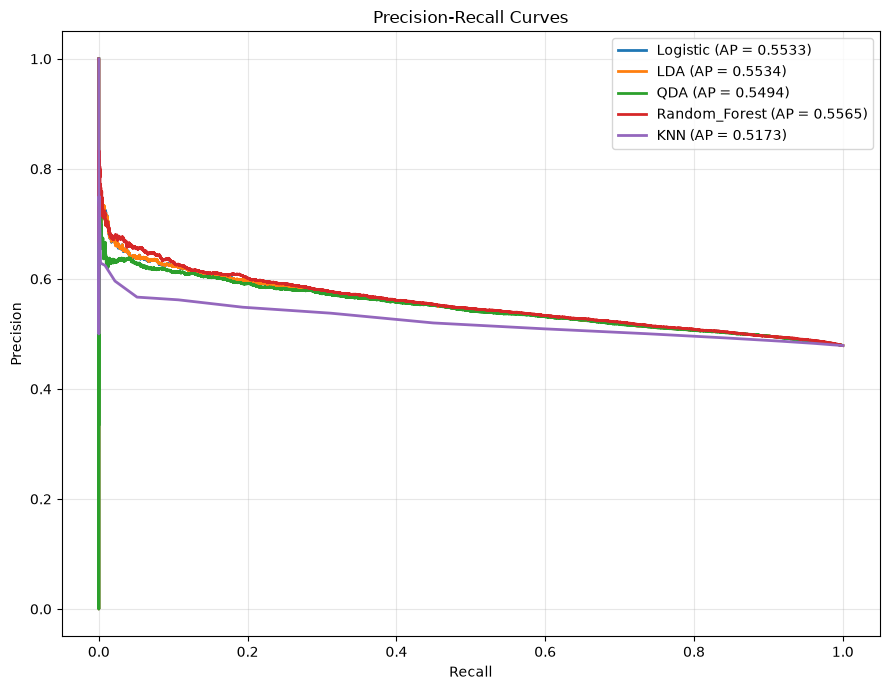


Model Comparison:
                ROC-AUC  PR-AUC (AP)
Random_Forest  0.584724     0.556545
LDA            0.582035     0.553366
Logistic       0.582024     0.553313
QDA            0.580105     0.549351
KNN            0.549758     0.517344


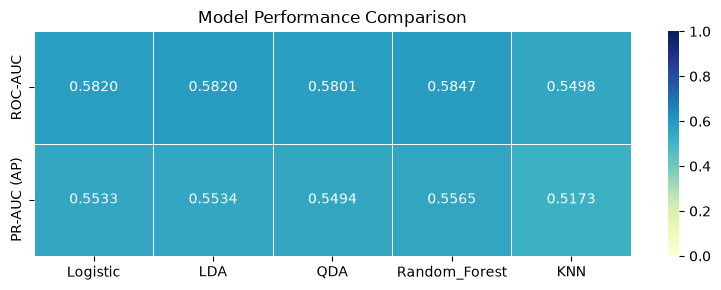

Dataset: BADS_WS2021_known
Detected models: ['Logistic', 'LDA', 'QDA', 'Random_Forest', 'KNN']


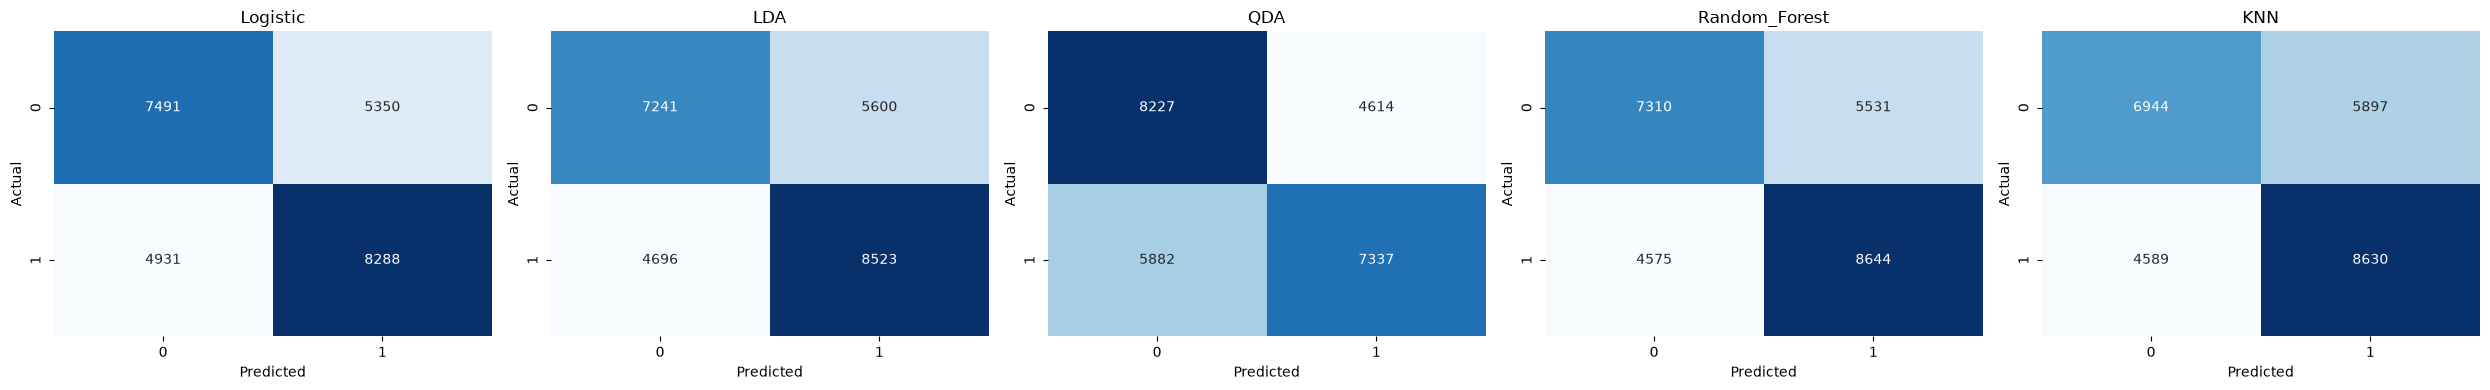

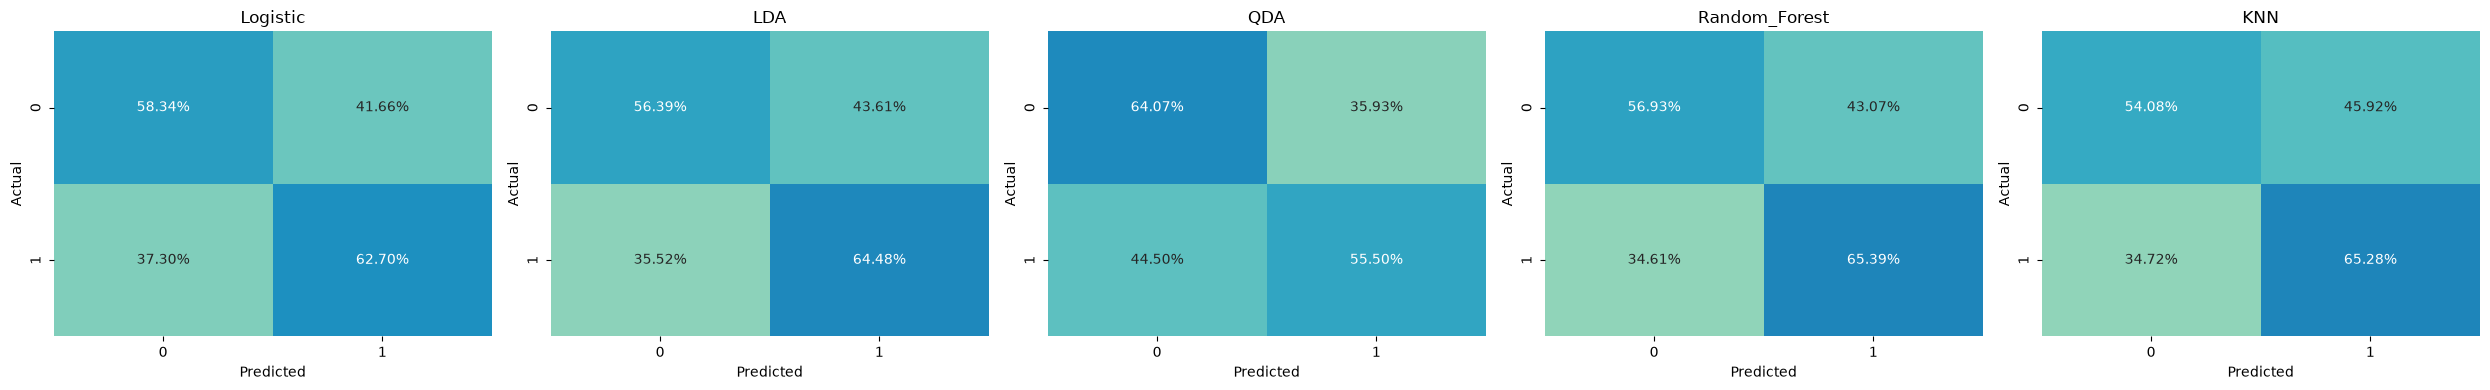

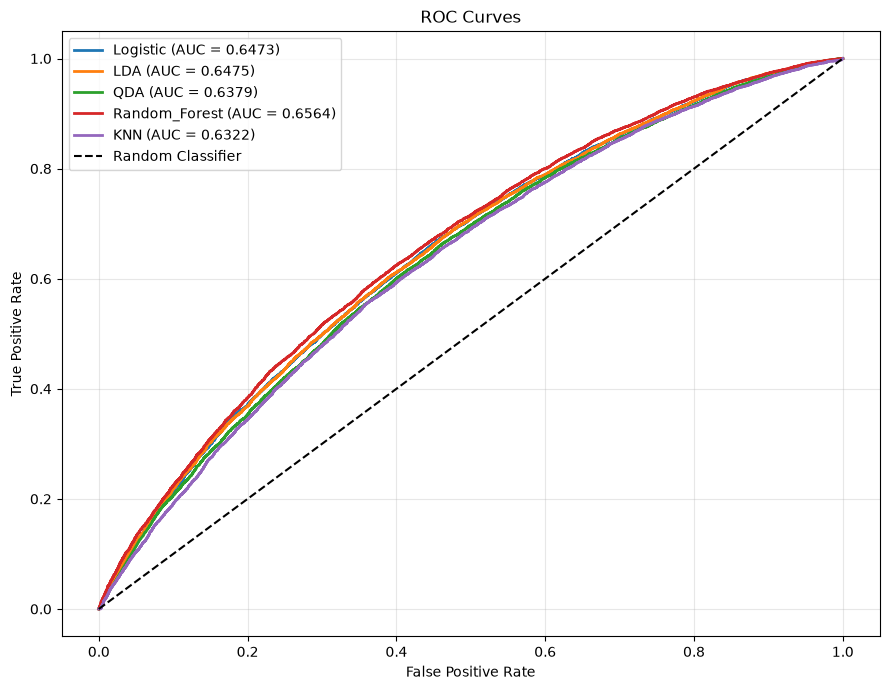

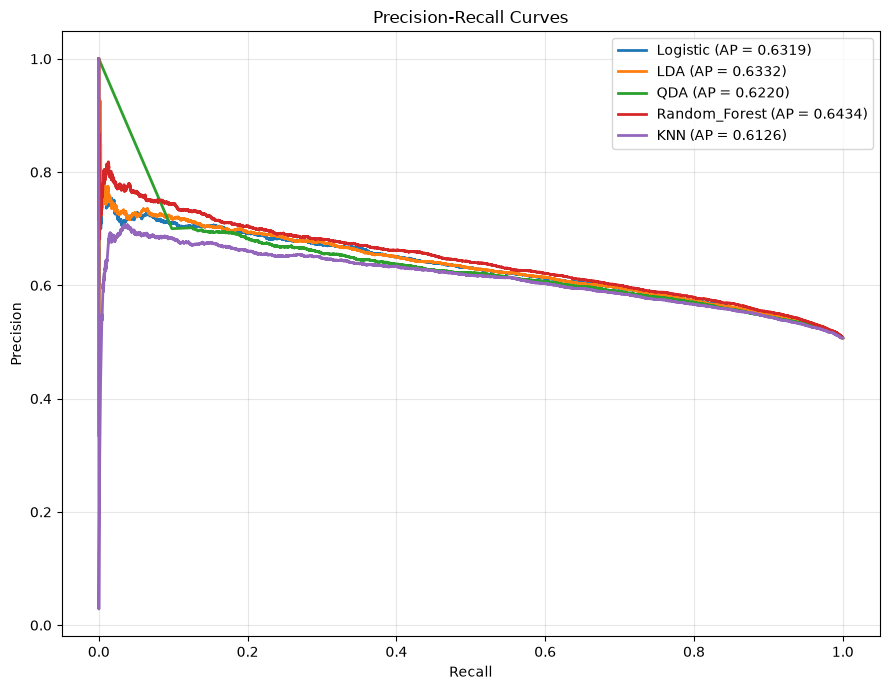


Model Comparison:
                ROC-AUC  PR-AUC (AP)
Random_Forest  0.656380     0.643367
LDA            0.647487     0.633161
Logistic       0.647273     0.631907
QDA            0.637927     0.621969
KNN            0.632188     0.612644


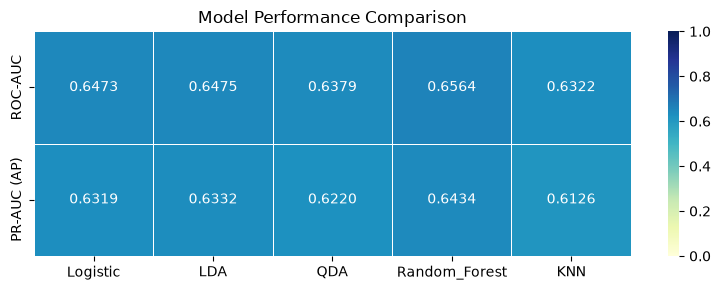

In [ ]:
all_results_df = pd.read_csv(os.path.join(OUTPUT_DIR, "all_model_results.csv"))
dataset_info_df = pd.read_csv(os.path.join(
    OUTPUT_DIR, "dataset_information.csv"))
parameters_df = pd.read_csv(os.path.join(
    OUTPUT_DIR, "all_best_parameters.csv"))

comparison_metrics = [
    "Accuracy",
    "Balanced_Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "ROC_AUC",
    "PR_AUC",
    "Log_Loss",
    "Brier_Score"
]

mean_comparison = (
    all_results_df
    .groupby("Model")[comparison_metrics]
    .mean()
)
std_comparison = (
    all_results_df
    .groupby("Model")[comparison_metrics]
    .std()
)

dataset_counts = (
    all_results_df
    .groupby("Model")["Dataset"]
    .nunique()
    .rename("Datasets_Evaluated")
)

ranking_metrics = [
    "ROC_AUC",
    "PR_AUC",
    "F1",
    "Balanced_Accuracy"
]

for metric in ranking_metrics:
    all_results_df[metric + "_Rank"] = (
        all_results_df
        .groupby("Dataset")[metric]
        .rank(
            ascending=False,
            method="average"
        )
    )

all_results_df["Log_Loss_Rank"] = (
    all_results_df
    .groupby("Dataset")["Log_Loss"]
    .rank(
        ascending=True,
        method="average"
    )
)

all_results_df["Brier_Score_Rank"] = (
    all_results_df
    .groupby("Dataset")["Brier_Score"]
    .rank(
        ascending=True,
        method="average"
    )
)

mean_ranks = (
    all_results_df
    .groupby("Model")[
        [
            "PR_AUC_Rank",
            "ROC_AUC_Rank",
            "F1_Rank",
            "Balanced_Accuracy_Rank",
            "Log_Loss_Rank",
            "Brier_Score_Rank"
        ]
    ]
    .mean()
)

# Combine into one overall leaderboard.
leaderboard = pd.concat([
    mean_comparison.add_suffix("_Mean"),
    std_comparison.add_suffix("_Std"),
    mean_ranks,
    dataset_counts
], axis=1)

leaderboard = leaderboard.sort_values(
    "ROC_AUC_Rank",
    ascending=True
)

leaderboard.to_csv(
    os.path.join(OUTPUT_DIR, "overall_leaderboard.csv")
)

best_per_dataset = (
    all_results_df
    .sort_values(
        ["Dataset", "PR_AUC"],
        ascending=[True, False]
    )
    .groupby("Dataset")
    .head(1)
    .reset_index(drop=True)
)

dataset_comparison = best_per_dataset[
    [
        "Dataset",
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC_AUC",
        "PR_AUC",
    ]
].merge(
    dataset_info_df,
    on="Dataset",
    how="left"
)

dataset_comparison.to_csv(
    os.path.join(OUTPUT_DIR, "dataset_comparison.csv"),
    index=False
)

dataset_predictions = {}
for dataset_name, config in DATASET_CONFIG.items():
    folder = os.path.join(INDIVIDUAL_DIR, safe_name(dataset_name))
    prediction_file = os.path.join(folder, "test_predictions.csv")

    if os.path.exists(prediction_file):
        pred_df = pd.read_csv(prediction_file)
        dataset_predictions[dataset_name] = pred_df


for i, (dataset_name, df) in enumerate(dataset_predictions.items()):
    folder = os.path.join(INDIVIDUAL_DIR, safe_name(dataset_name))
    models = {}

    for col in df.columns:
        if col.endswith("_prediction"):
            model = col.removesuffix("_prediction")

            probability_col = f"{model}_probability"

            models[model] = {
                "prediction": col,
                "probability": (
                    probability_col if probability_col in df.columns else None
                )
            }

    print("Dataset:", dataset_name)
    print("Detected models:", list(models.keys()))

    y_true = df["Actual"]

    n_models = len(models)

    fig, axes = plt.subplots(
        1, n_models,
        figsize=(5 * n_models, 4)
    )

    if n_models == 1:
        axes = [axes]

    for ax, (model, cols) in zip(axes, models.items()):

        y_pred = df[cols["prediction"]]

        cm = confusion_matrix(y_true, y_pred)

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            cbar=False,
            ax=ax
        )

        ax.set_title(model)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

    plt.tight_layout()
    plt.savefig(os.path.join(folder, "confusion_matrices.png"), dpi=300)
    plt.show()

    fig, axes = plt.subplots(
        1, n_models,
        figsize=(5 * n_models, 4)
    )

    if n_models == 1:
        axes = [axes]

    for ax, (model, cols) in zip(axes, models.items()):

        cm = confusion_matrix(
            y_true,
            df[cols["prediction"]],
            normalize="true"
        )

        sns.heatmap(
            cm,
            annot=True,
            fmt=".2%",
            cmap="YlGnBu",
            vmin=0,
            vmax=1,
            cbar=False,
            ax=ax
        )

        ax.set_title(model)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

    plt.tight_layout()
    plt.savefig(os.path.join(
        folder, "normalized_confusion_matrices.png"), dpi=300)
    plt.show()

    plt.figure(figsize=(9, 7))

    roc_results = {}

    for model, cols in models.items():

        prob_col = cols["probability"]

        if prob_col is None:
            continue

        y_prob = df[prob_col]

        auc = roc_auc_score(y_true, y_prob)

        fpr, tpr, _ = roc_curve(y_true, y_prob)

        roc_results[model] = auc

        plt.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{model} (AUC = {auc:.4f})"
        )

    plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curves")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(folder, "roc_curves.png"), dpi=300)
    plt.show()

    plt.figure(figsize=(9, 7))

    pr_results = {}

    for model, cols in models.items():

        prob_col = cols["probability"]

        if prob_col is None:
            continue

        y_prob = df[prob_col]

        precision, recall, _ = precision_recall_curve(
            y_true, y_prob
        )

        ap = average_precision_score(y_true, y_prob)

        pr_results[model] = ap

        plt.plot(
            recall,
            precision,
            linewidth=2,
            label=f"{model} (AP = {ap:.4f})"
        )

    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("Precision-Recall Curves")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(folder, "pr_curves.png"), dpi=300)
    plt.show()

    metrics_df = pd.DataFrame({
        "ROC-AUC": roc_results,
        "PR-AUC (AP)": pr_results
    })

    print("\nModel Comparison:")
    print(metrics_df.sort_values("PR-AUC (AP)", ascending=False))

    plt.figure(figsize=(8, 3))

    sns.heatmap(
        metrics_df.T,
        annot=True,
        fmt=".4f",
        cmap="YlGnBu",
        vmin=0,
        vmax=1,
        linewidths=0.5
    )

    plt.title("Model Performance Comparison")
    plt.tight_layout()
    plt.savefig(os.path.join(folder, "auc_comparison.png"), dpi=300)
    plt.show()


## 7. PLOT: DATASET RETURN RATES

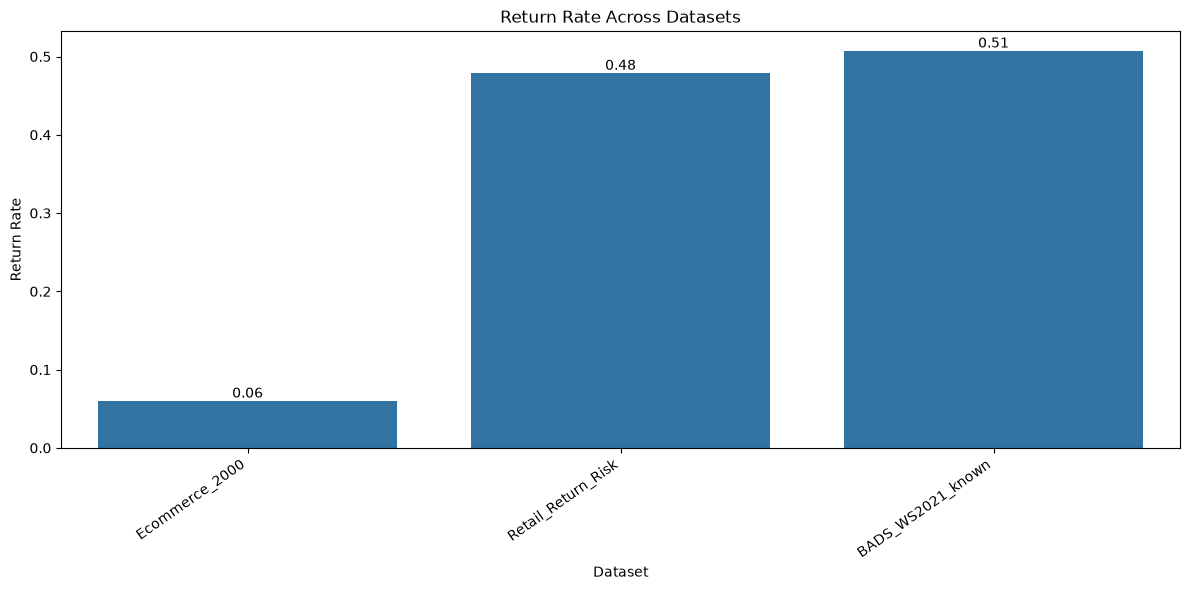

In [ ]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=dataset_info_df,
    x="Dataset",
    y="Return_Rate"
)

ax.bar_label(ax.containers[0], fmt="%.2f",
             label_type="edge", fontsize=10, color="black")

plt.ylabel("Return Rate")
plt.title("Return Rate Across Datasets")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.savefig(
    os.path.join(PLOT_DIR, "dataset_return_rates.png"),
    dpi=200
)
plt.show()
plt.close()


## 10. PLOT: MODEL PERFORMANCE ACROSS DATASETS

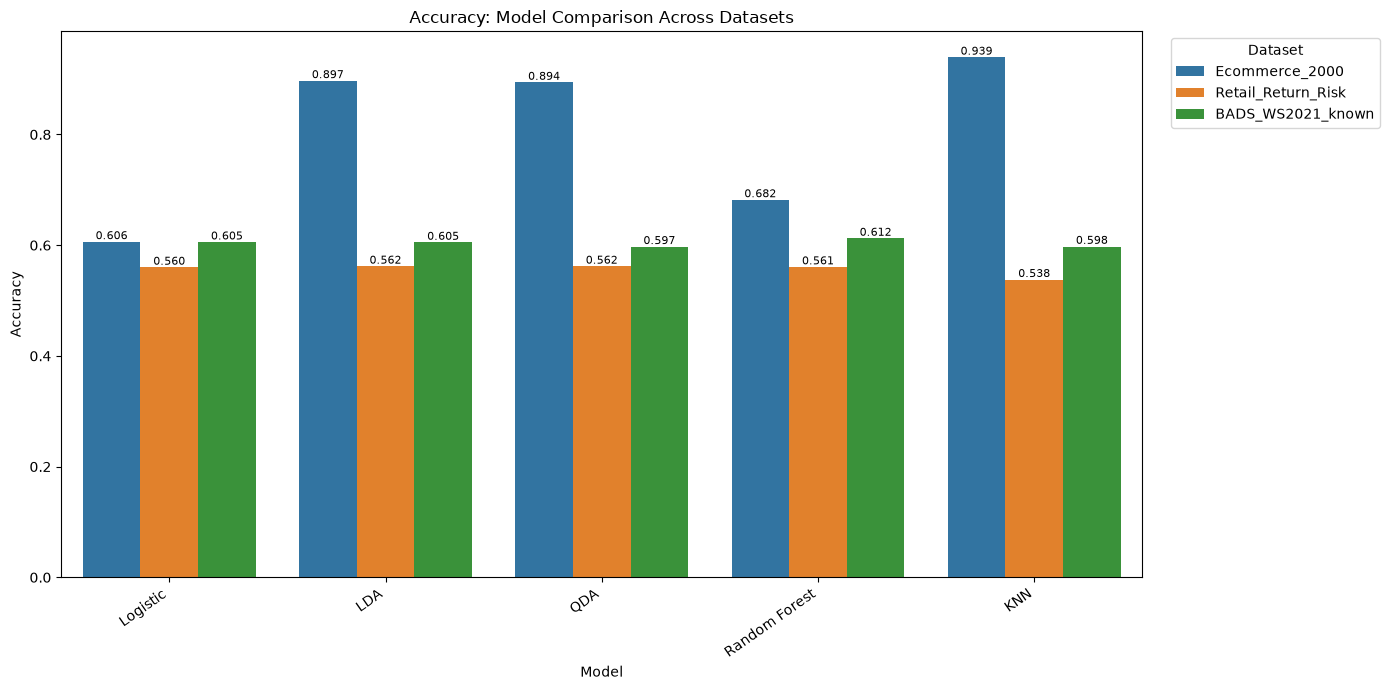

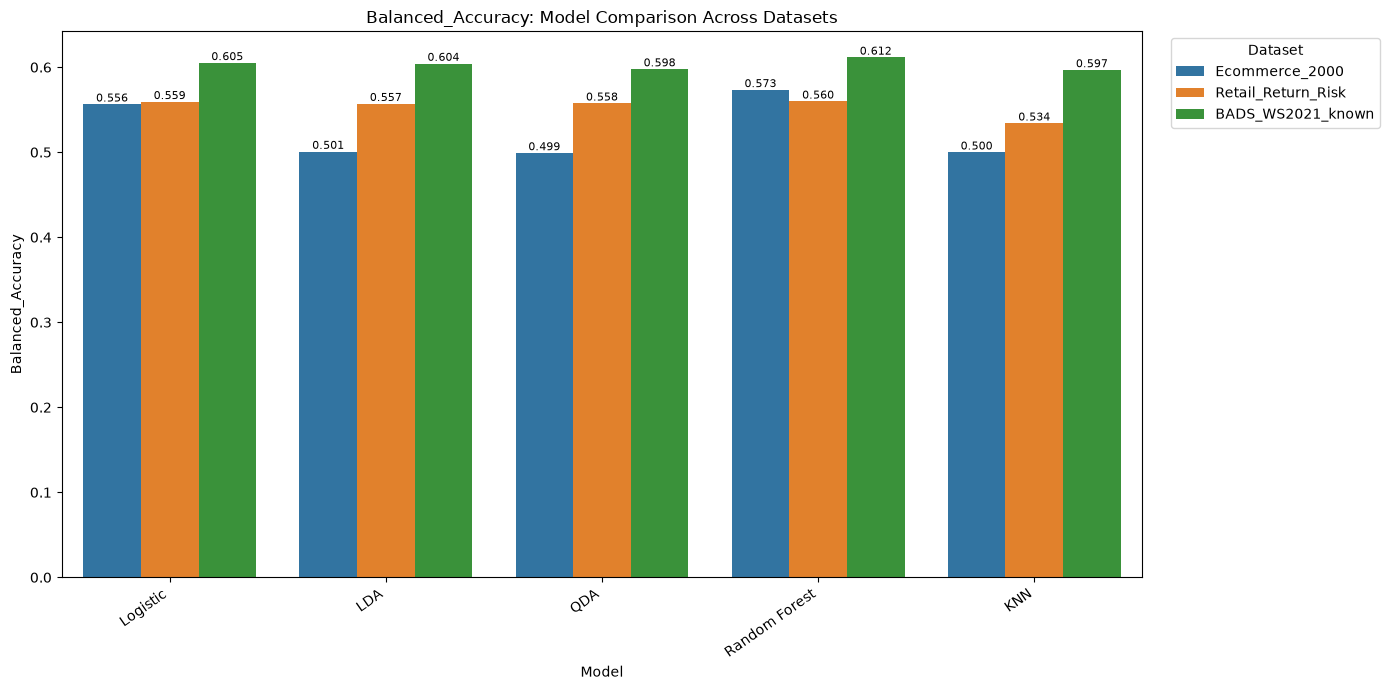

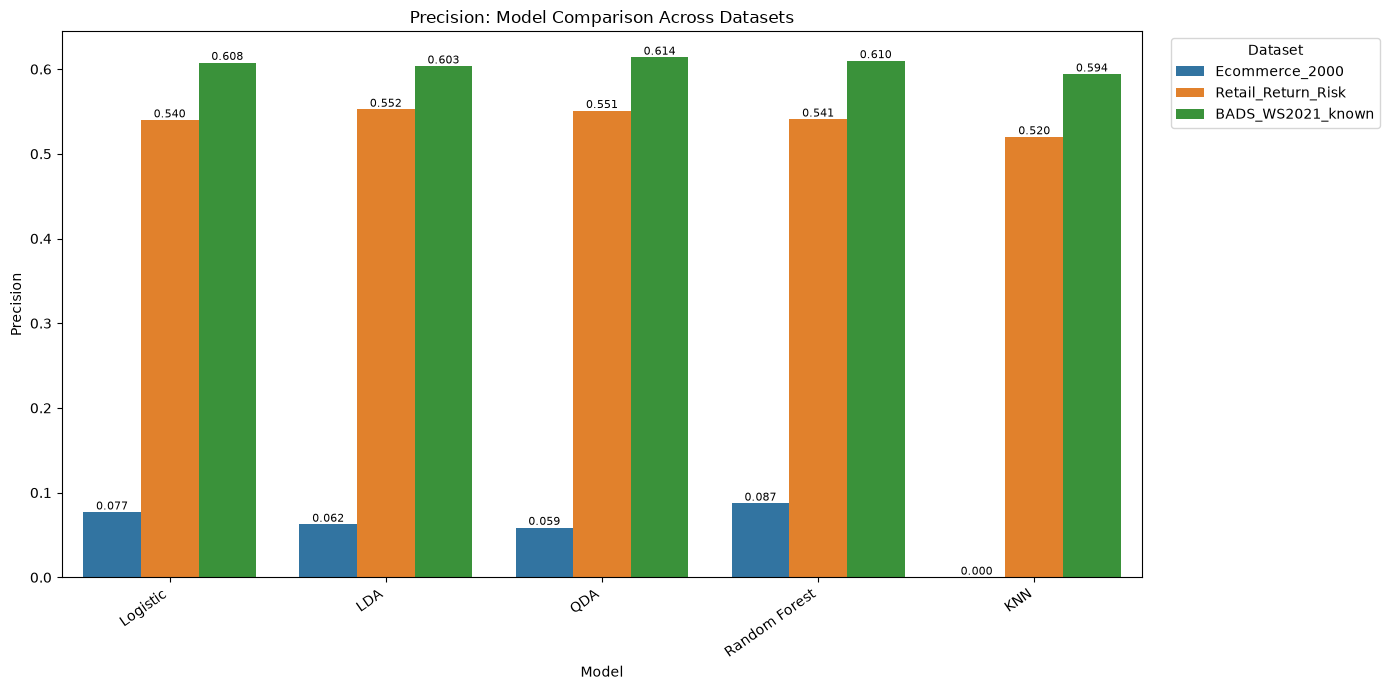

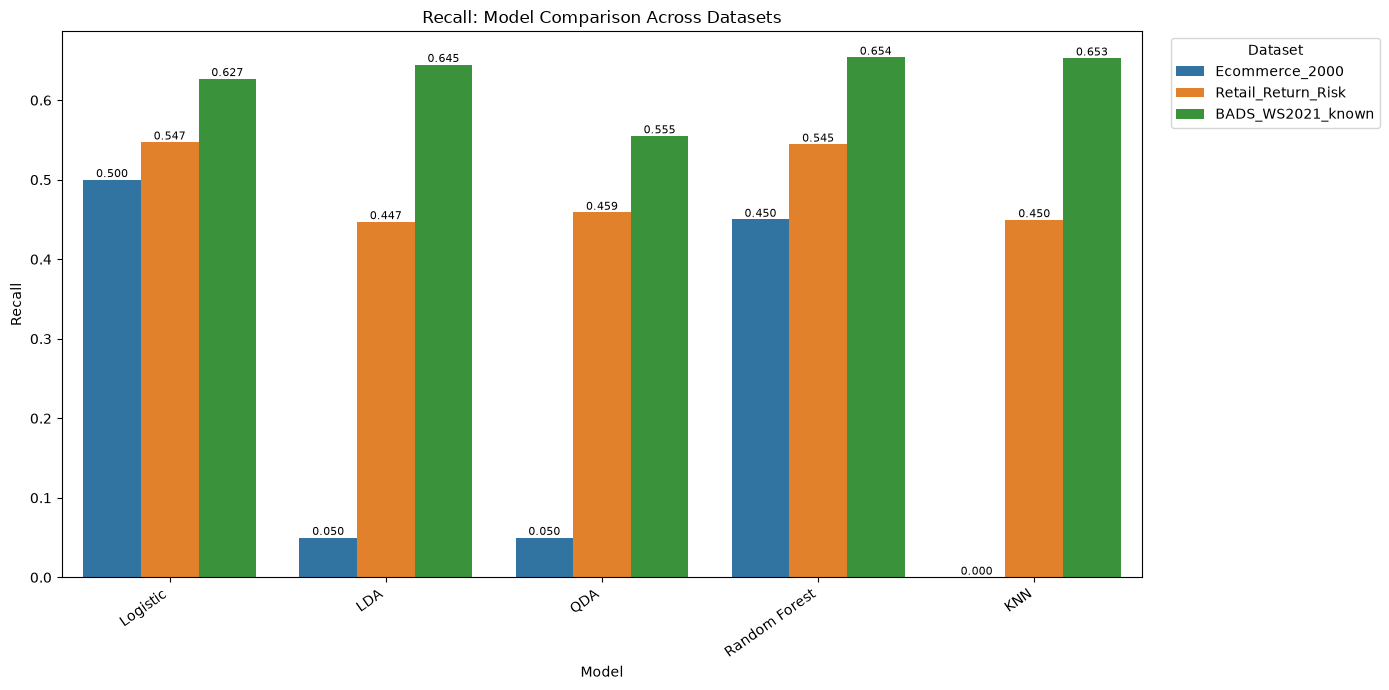

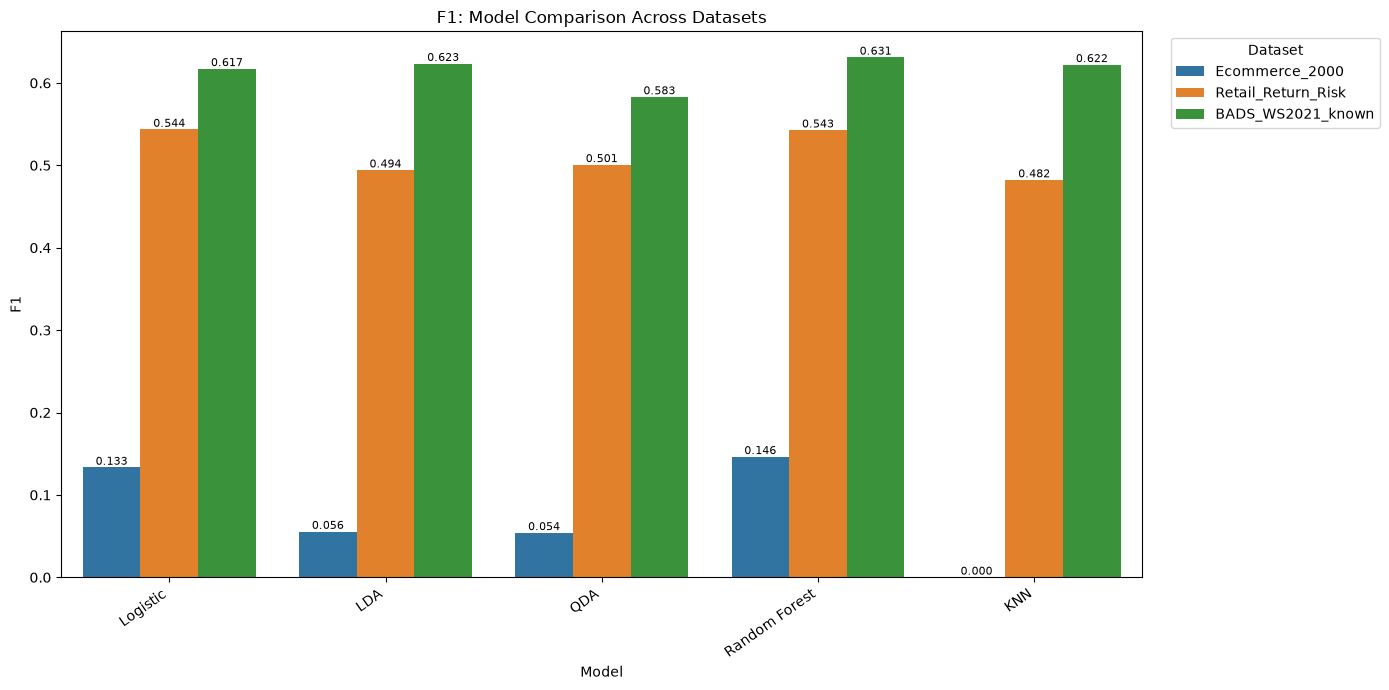

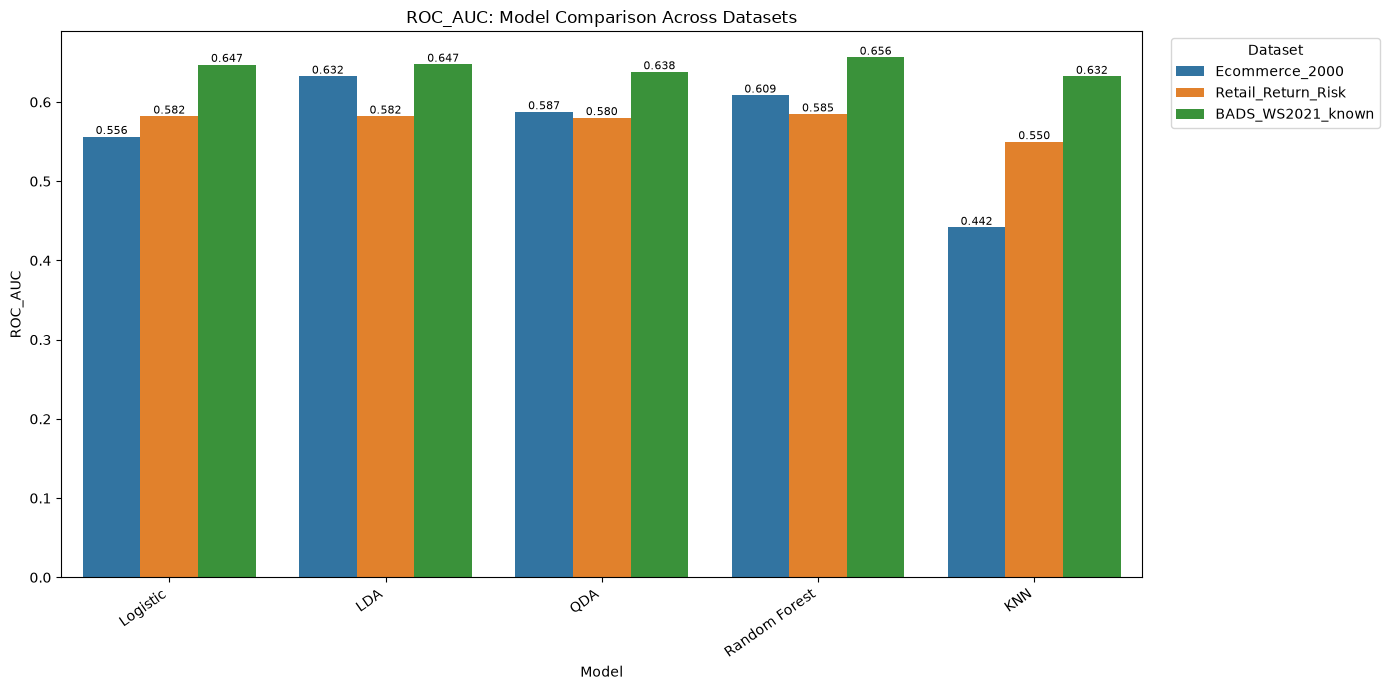

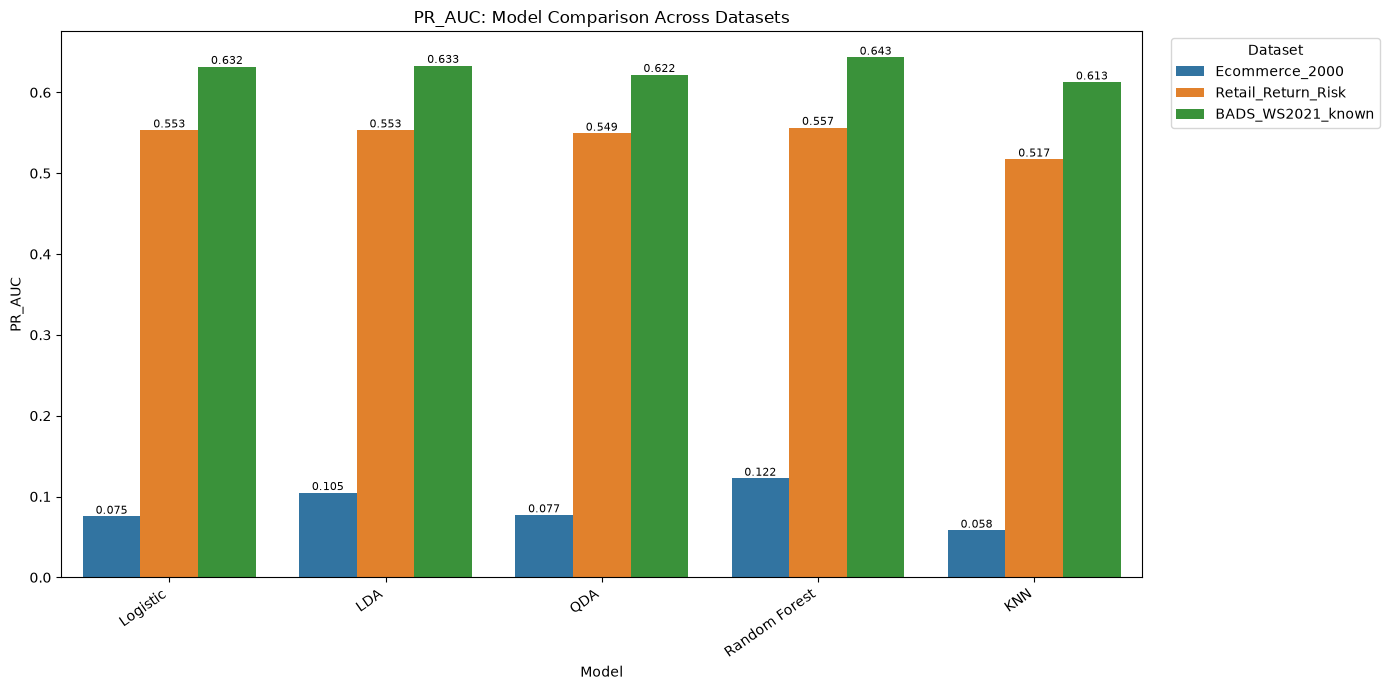

In [ ]:
plot_metrics = [
    "Accuracy",
    "Balanced_Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC",
]

for metric in plot_metrics:

    plt.figure(figsize=(14, 7))

    ax = sns.barplot(
        data=all_results_df,
        x="Model",
        y=metric,
        hue="Dataset"
    )

    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=8, color="black")

    plt.title(
        f"{metric}: Model Comparison Across Datasets"
    )

    plt.xticks(rotation=35, ha="right")
    plt.legend(
        title="Dataset",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.savefig(
        os.path.join(
            PLOT_DIR,
            f"{metric}_across_datasets.png"
        ),
        dpi=200
    )
    plt.show()
    plt.close()


## 11. PLOT: OVERALL MODEL LEADERBOARD

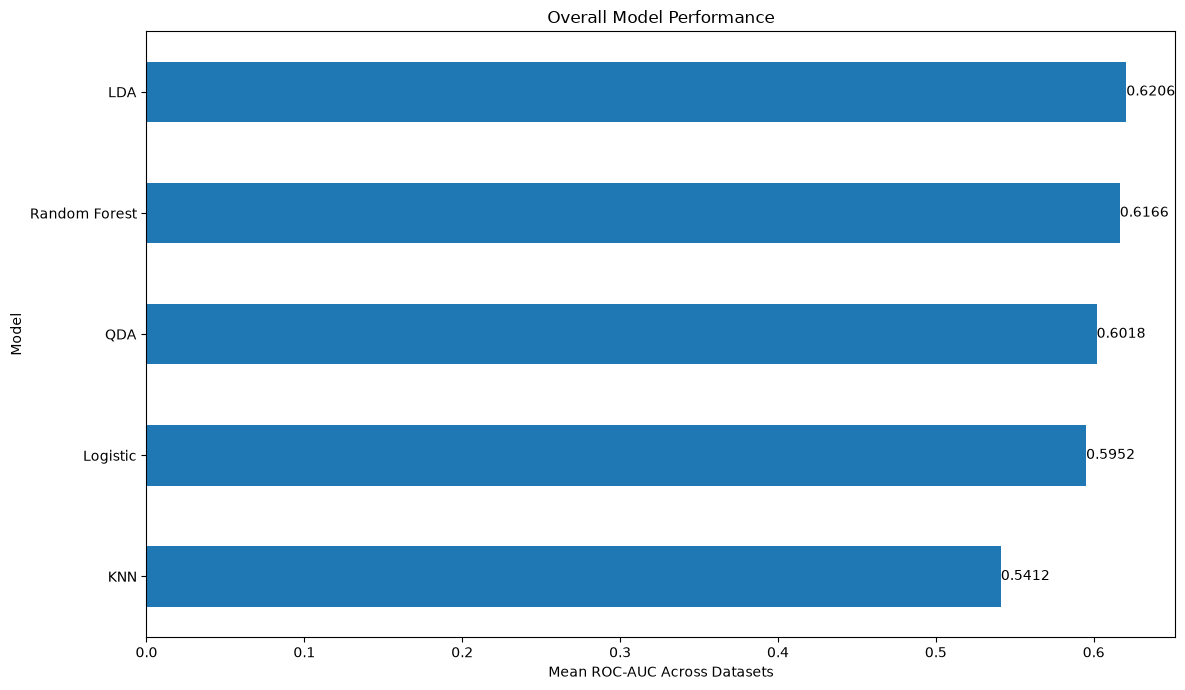

In [ ]:
plt.figure(figsize=(12, 7))

ax = leaderboard["ROC_AUC_Mean"].sort_values().plot(
    kind="barh"
)

ax.bar_label(ax.containers[0], fmt="%.4f",
             label_type="edge", fontsize=10, color="black")

plt.xlabel("Mean ROC-AUC Across Datasets")
plt.title("Overall Model Performance")

plt.tight_layout()
plt.savefig(
    os.path.join(PLOT_DIR, "overall_model_performance.png"),
    dpi=200
)
plt.show()
plt.close()


## 12. PLOT: AVERAGE MODEL RANKING

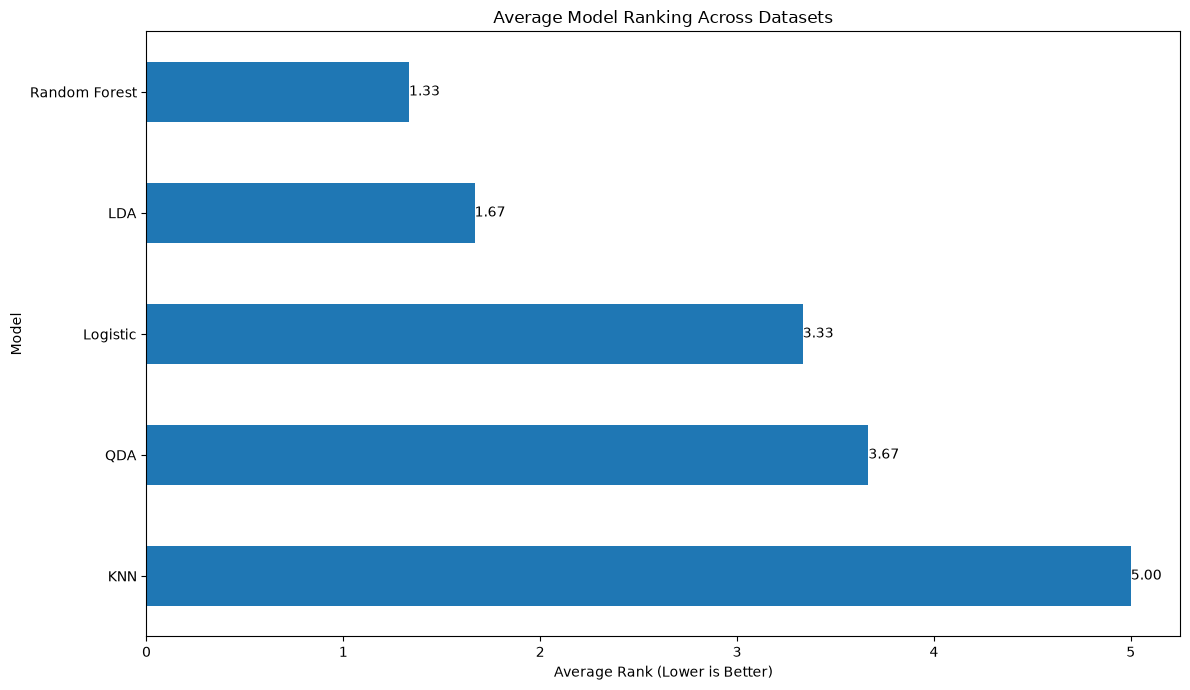

In [ ]:
plt.figure(figsize=(12, 7))

ax = mean_ranks["ROC_AUC_Rank"].sort_values(
    ascending=False
).plot(kind="barh")

ax.bar_label(ax.containers[0], fmt="%.2f",
             label_type="edge", fontsize=10, color="black")

plt.xlabel("Average Rank (Lower is Better)")
plt.title("Average Model Ranking Across Datasets")

plt.tight_layout()
plt.savefig(
    os.path.join(PLOT_DIR, "average_model_ranking.png"),
    dpi=200
)
plt.show()
plt.close()


## 14. FINAL SUMMARY

In [ ]:
print("\nBEST MODEL FOR EACH DATASET:")
print(
    dataset_comparison[
        ["Dataset", "Model", "ROC_AUC", "PR_AUC", "F1"]
    ].to_string(index=False)
)

print("\nOVERALL MODEL LEADERBOARD:")
print(
    leaderboard[
        [
            "Datasets_Evaluated",
            "ROC_AUC_Mean",
            "ROC_AUC_Std",
            "ROC_AUC_Rank",
            "PR_AUC_Mean",
            "PR_AUC_Std",
            "PR_AUC_Rank",
            "F1_Mean",
            "F1_Std",
            "F1_Rank"
        ]
    ].to_string()
)

print("\nALL RESULTS SAVED IN:", OUTPUT_DIR)



BEST MODEL FOR EACH DATASET:
           Dataset         Model  ROC_AUC   PR_AUC       F1
 BADS_WS2021_known Random Forest 0.656380 0.643367 0.631087
    Ecommerce_2000 Random Forest 0.608548 0.122420 0.146341
Retail_Return_Risk Random Forest 0.584724 0.556545 0.542706

OVERALL MODEL LEADERBOARD:
               Datasets_Evaluated  ROC_AUC_Mean  ROC_AUC_Std  ROC_AUC_Rank  PR_AUC_Mean  PR_AUC_Std  PR_AUC_Rank   F1_Mean    F1_Std   F1_Rank
Model                                                                                                                                         
Random Forest                   3      0.616551     0.036492      1.333333     0.440777    0.279102     1.000000  0.440045  0.258165  1.333333
LDA                             3      0.620647     0.034277      1.666667     0.430407    0.284883     2.000000  0.391061  0.297656  3.000000
Logistic                        3      0.595196     0.046900      3.333333     0.420206    0.301186     3.333333  0.431354  0.2607